# Page Turners: book popularity and reader ratings

This notebook explores the relationship between popularity and ratings,
compares authors, selected genres and publication periods, measures
reader disagreement, and examines rankings adjusted for rating counts.

Run the notebook from the repository root or its `notebooks` folder.
The repository must include the `page_turners` package with `__init__.py`,
`data.py`, `analysis.py`, `plots.py`, `api.py` and `scoring.py`, plus
`books.csv` in the project root. The data module must provide
`load_books`, `prepare_books` and `load_tag_data`. Dependencies are
`numpy`, `pandas`, `scipy`, `matplotlib`, `requests` and Jupyter/IPython.
The genre section downloads tag tables from the goodbooks-10k repository,
and the optional online lookup needs internet access.

In Colab, the setup below also supports the existing
`MyDrive/page-turners` folder. This notebook imports the existing package
modules rather than writing or modifying their source files.


In [1]:
import os
import sys
from pathlib import Path

# Prefer a local repository; retain the existing Colab workflow.
project_root = next(
    (
        candidate
        for candidate in (Path.cwd(), Path.cwd().parent)
        if (candidate / "page_turners" / "data.py").is_file()
    ),
    None
)

if project_root is None:
    try:
        from google.colab import drive
    except ImportError as error:
        raise FileNotFoundError(
            "Run from the repository root or its notebooks folder, "
            "with page_turners/data.py included."
        ) from error

    drive.mount("/content/drive")
    project_root = Path("/content/drive/MyDrive/page-turners")

project_dir = str(project_root)
package_dir = os.path.join(project_dir, "page_turners")

if project_dir not in sys.path:
    sys.path.insert(0, project_dir)


Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from page_turners.data import load_books, prepare_books, load_tag_data
import page_turners.analysis as analysis
import page_turners.plots as plots
import page_turners.api as api
import page_turners.scoring as scoring

books_path = os.path.join(project_dir, "books.csv")
books = load_books(books_path)

print(books.shape)
books.head()

(10000, 23)


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


In [3]:
books.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   book_id                    10000 non-null  int64  
 1   goodreads_book_id          10000 non-null  int64  
 2   best_book_id               10000 non-null  int64  
 3   work_id                    10000 non-null  int64  
 4   books_count                10000 non-null  int64  
 5   isbn                       9300 non-null   object 
 6   isbn13                     9415 non-null   float64
 7   authors                    10000 non-null  object 
 8   original_publication_year  9979 non-null   float64
 9   original_title             9415 non-null   object 
 10  title                      10000 non-null  object 
 11  language_code              8916 non-null   object 
 12  average_rating             10000 non-null  float64
 13  ratings_count              10000 non-null  int6

In [4]:
books[
    [
        "original_publication_year",
        "average_rating",
        "ratings_count",
        "work_ratings_count"
    ]
].describe()

,original_publication_year,average_rating,ratings_count,work_ratings_count
count,9979.000000,10000.000000,1.000000e+04,1.000000e+04
mean,1981.987674,4.002191,5.400124e+04,5.968732e+04
std,152.576665,0.254427,1.573700e+05,1.678038e+05
min,-1750.000000,2.470000,2.716000e+03,5.510000e+03
25%,1990.000000,3.850000,1.356875e+04,1.543875e+04
50%,2004.000000,4.020000,2.115550e+04,2.383250e+04
75%,2011.000000,4.180000,4.105350e+04,4.591500e+04
max,2017.000000,4.820000,4.780653e+06,4.942365e+06


Data quality checks
Before cleaning the dataset, I check for missing values and repeated book identifiers. These checks help determine whether any corrections are necessary without removing valid observations.

In [5]:
missing_values = books.isna().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])

print("\nRepeated book IDs:")
print(books["book_id"].duplicated().sum())

Columns with missing values:
isbn                          700
isbn13                        585
original_publication_year      21
original_title                585
language_code                1084
dtype: int64

Repeated book IDs:
0


Some publication years are negative. I inspect these records before cleaning them because negative years may represent ancient works.

In [6]:
books.loc[
    books["original_publication_year"] < 0,
    ["title", "authors", "original_publication_year"]
].sort_values("original_publication_year").head(10)

,title,authors,original_publication_year
2075,The Epic of Gilgamesh,"Anonymous, N.K. Sandars",-1750.0
2141,The Iliad/The Odyssey,"Homer, Robert Fagles, Bernard Knox",-762.0
340,The Iliad,"Homer, Robert Fagles, Frédéric Mugler, Bernard...",-750.0
6165,The I Ching or Book of Changes,"Anonymous, Richard Wilhelm, Cary F. Baynes, C....",-750.0
78,The Odyssey,"Homer, Robert Fagles, E.V. Rieu, Frédéric Mugl...",-720.0
1119,Aesop's Fables,"Aesop, Laura Harris, Laura Gibbs",-560.0
5636,The Dhammapada,"Anonymous, Ananda Maitreya, Thich Nhat Hanh, B...",-500.0
402,The Art of War,"Sun Tzu, Thomas Cleary",-500.0
9678,The Upanishads: Translations from the Sanskrit,"Anonymous, Juan Mascaró",-500.0
7777,The Analects,"Confucius, D.C. Lau",-476.0


Negative publication years are retained because the records refer to ancient works. Missing years remain unknown rather than being replaced with an invented date. Publication years are stored using pandas’ nullable integer type.

In [7]:
books_clean = prepare_books(books)

print("Rows and columns:", books_clean.shape)
print("Year type:", books_clean["original_publication_year"].dtype)
print("Missing years:", books_clean["original_publication_year"].isna().sum())

Rows and columns: (10000, 23)
Year type: Int64
Missing years: 21


In [8]:
print(package_dir)

/content/drive/MyDrive/page-turners/page_turners


> **Books with the most ratings**


I first examine books with the highest rating counts. This provides a measure of reader attention, which I will later compare with average ratings.

In [12]:
columns_to_show = [
    "title",
    "authors",
    "work_ratings_count",
    "average_rating"
]

most_rated = analysis.top_books(
    books_clean,
    sort_by="work_ratings_count",
    n=10
)

most_rated.loc[:, columns_to_show]

,title,authors,work_ratings_count,average_rating
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4942365,4.34
1,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4800065,4.44
2,"Twilight (Twilight, #1)",Stephenie Meyer,3916824,3.57
3,To Kill a Mockingbird,Harper Lee,3340896,4.25
4,The Great Gatsby,F. Scott Fitzgerald,2773745,3.89
5,The Fault in Our Stars,John Green,2478609,4.26
11,"Divergent (Divergent, #1)",Veronica Roth,2216814,4.24
6,The Hobbit,J.R.R. Tolkien,2196809,4.25
9,Pride and Prejudice,Jane Austen,2191465,4.24
7,The Catcher in the Rye,J.D. Salinger,2120637,3.79


In [13]:
highest_rated = analysis.top_books(
    books_clean,
    sort_by="average_rating",
    n=10
)

highest_rated.loc[:, columns_to_show]

,title,authors,work_ratings_count,average_rating
3627,The Complete Calvin and Hobbes,Bill Watterson,29968,4.82
861,"Words of Radiance (The Stormlight Archive, #2)",Brandon Sanderson,108176,4.77
3274,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré",33424,4.77
7946,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem",10784,4.76
8853,Mark of the Lion Trilogy,Francine Rivers,9547,4.76
4482,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson,23429,4.75
6360,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson,17285,4.74
421,"Harry Potter Boxset (Harry Potter, #1-7)",J.K. Rowling,204125,4.74
3752,"Harry Potter Collection (Harry Potter, #1-6)",J.K. Rowling,26274,4.73
6919,The Indispensable Calvin and Hobbes,Bill Watterson,16911,4.73


In [15]:
rho = analysis.popularity_correlation(books_clean)
print(f"Spearman correlation: {rho:.4f}")

Spearman correlation: 0.0792


Among these books, popularity—measured by the number of ratings—has a very weak positive association with average rating (Spearman ρ ≈ 0.079).

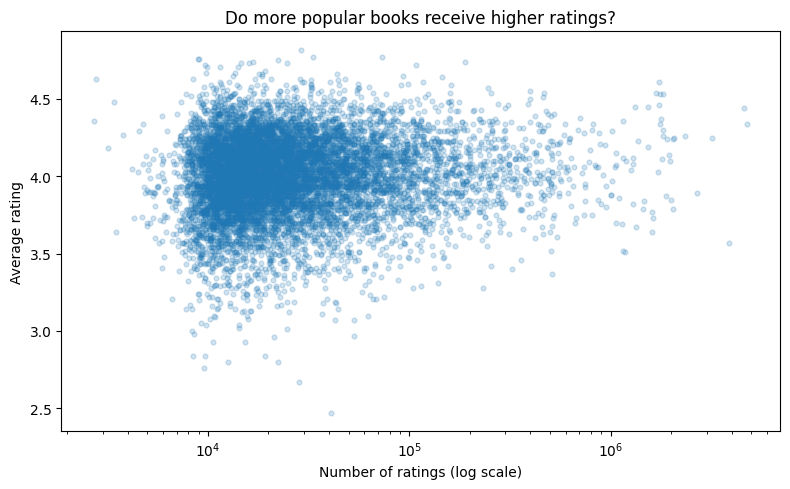

In [17]:
fig, ax = plots.plot_popularity_vs_rating(books_clean)
plt.show()

## How do ratings vary across publication periods?

I divide books into four publication periods and compare their
average ratings. Books with missing publication years are excluded
from this comparison, while ancient works with negative years are retained.
Each book contributes equally to the summaries.


In [18]:
# Group books by publication period and calculate summary statistics.
period_books, period_summary = analysis.publication_period_analysis(
    books_clean
)

# Display the summary table.
period_summary

,period,book_count,mean_rating,median_rating
0,Before 1900,379,3.941003,3.94
1,1900–1949,466,4.032876,4.06
2,1950–1999,2946,4.034134,4.05
3,2000 onwards,6188,3.987912,4.01


In this dataset, average ratings differ only slightly across publication periods. Books published between 1900 and 1999 have the highest means, while those published before 1900 have the lowest. These descriptive differences do not establish a causal relationship.

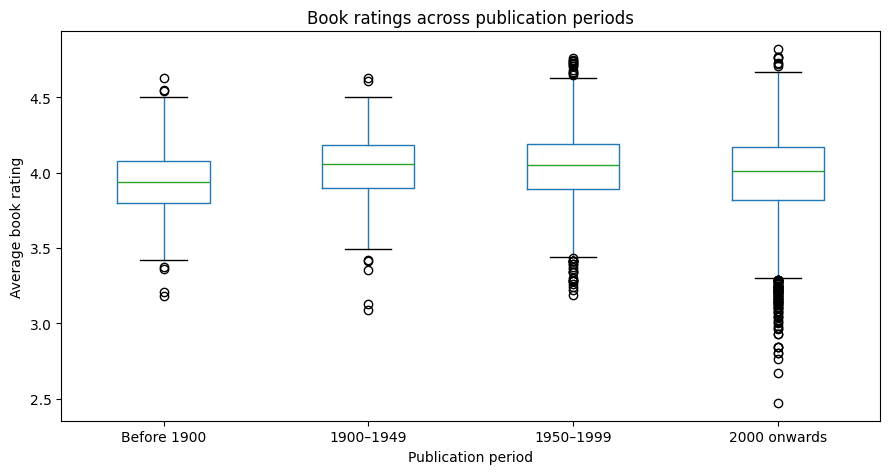

In [19]:
# Compare rating distributions across publication periods.
fig, ax = plots.plot_ratings_by_period(period_books)

plt.show()

Rating distributions overlap substantially across publication periods. Twentieth-century books have slightly higher typical ratings, but the differences are small. Group sizes differ considerably, and valid outlying ratings were retained.

## How do ratings differ across authors?

I compare authors using the mean and median ratings of their books.
Each book contributes equally.

The authors field can include several contributors. For this analysis,
I group books by the first listed name. This is a practical convention,
rather than a verified identification of the main author.

I exclude “Anonymous” and compare authors with at least five books
in this dataset. This threshold avoids comparisons based on a single book.

In [21]:
author_summary = analysis.author_rating_summary(
    books_clean,
    min_books=5
)

print(f"Authors with at least five books: {len(author_summary)}")

# Show the ten authors with the highest mean book ratings.
author_summary.head(10)

Authors with at least five books: 472


,primary_author,book_count,mean_rating,median_rating
0,Bill Watterson,13,4.703077,4.710
1,Sarah J. Maas,13,4.453077,4.480
2,J.K. Rowling,20,4.399000,4.450
3,A.A. Milne,6,4.386667,4.370
4,Bisco Hatori,6,4.381667,4.445
5,Natsuki Takaya,7,4.380000,4.390
6,Dee Henderson,6,4.370000,4.385
7,Derek Landy,5,4.370000,4.400
8,Karen Kingsbury,10,4.369000,4.385
9,Tsugumi Ohba,9,4.360000,4.390


### Authors with the highest mean book ratings

The chart shows the ten highest mean ratings among authors with at
least five books in the dataset. Labels show the number of books
included for each author. Each book contributes equally.

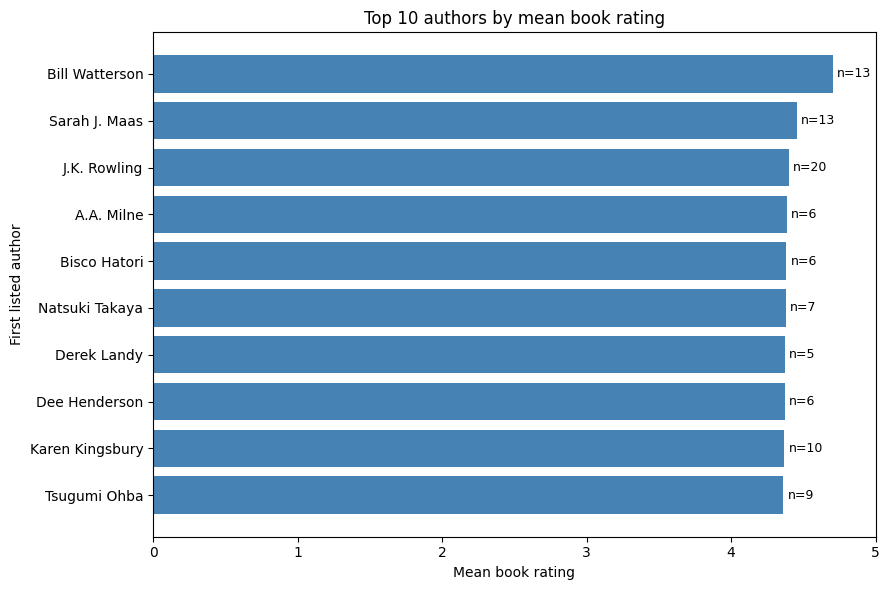

In [23]:
fig, ax = plots.plot_top_authors(author_summary, n=10)
plt.show()

Among the 472 authors represented by at least five books,
Bill Watterson has the highest mean book rating: approximately
4.70 across 13 books. Sarah J. Maas follows at approximately
4.45, and J.K. Rowling at 4.40.

These results describe the books included in this dataset,
rather than each author's complete bibliography. Each book
contributes equally, regardless of its number of reader ratings.
The chart displays only the ten highest means.

## How do ratings differ across genres?

I use the dataset's book tags to identify genres. Tags also include
personal reading shelves, so only selected genre tags will be used.

A book can belong to more than one genre.

In [24]:
data_url = (
    "https://raw.githubusercontent.com/"
    "zygmuntz/goodbooks-10k/master"
)

# Call the function saved in data.py.
tags, book_tags = load_tag_data(
    tags_source=f"{data_url}/tags.csv",
    book_tags_source=f"{data_url}/book_tags.csv"
)

print("Tag table dimensions:", tags.shape)
print("Book-tag table dimensions:", book_tags.shape)

Tag table dimensions: (34252, 2)
Book-tag table dimensions: (999912, 3)


In [25]:
# Inspect the identifiers and names in each table.
print("Tag names:")
display(tags.head())

print("Links between books and tags:")
display(book_tags.head())

Tag names:


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


Links between books and tags:


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716


### Compare book ratings across selected genres

I select eight genre categories using reader-assigned tags.
Alternative spellings, such as “sci-fi” and “science-fiction”,
are grouped together.

Each book contributes once to every category to which it belongs.
Ratings are averaged equally across books, without weighting by
the number of ratings or tag assignments.

These categories overlap and reflect reader labels rather than
an official classification.

In [27]:
# Combine alternative tag names under the same category.
genre_map = {
    "fantasy": "Fantasy",
    "romance": "Romance",
    "science-fiction": "Science fiction",
    "sci-fi": "Science fiction",
    "mystery": "Mystery",
    "thriller": "Thriller",
    "horror": "Horror",
    "historical-fiction": "Historical fiction",
    "non-fiction": "Nonfiction",
    "nonfiction": "Nonfiction"
}

genre_books, genre_summary = analysis.genre_rating_analysis(
    books_clean,
    book_tags,
    tags,
    genre_map
)

# Report how many distinct books received a selected category.
print(
    "Books assigned at least one selected category:",
    genre_books["book_id"].nunique()
)

# Compare ratings across the selected categories.
genre_summary

Books assigned at least one selected category: 9713


,genre,book_count,mean_rating,median_rating
0,Fantasy,4259,4.058410,4.07
1,Science fiction,2471,4.035856,4.05
2,Nonfiction,2153,4.018783,4.04
3,Romance,4251,3.998908,4.02
4,Horror,1372,3.988462,3.99
5,Mystery,3686,3.982702,3.99
6,Thriller,2522,3.969167,3.98
7,Historical fiction,2590,3.965676,3.98


### Distribution of book ratings across genres

The box plot compares the distributions of average book ratings
within each category. Each observation represents one book's
average rating, rather than an individual reader's rating.

A book can appear in several categories.

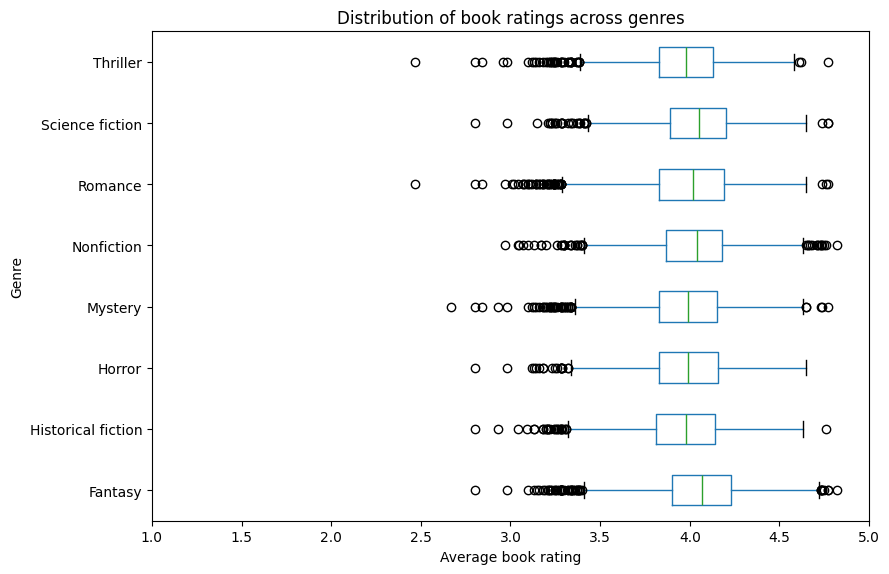

In [29]:
fig, ax = plots.plot_ratings_by_genre(genre_books)
plt.show()

Fantasy has the highest mean book rating among the selected
categories, approximately 4.06. Historical fiction has the lowest,
approximately 3.97. The difference is only about 0.09 rating points.

The selected categories cover 9,713 of the 10,000 books.
Category sizes differ, and their memberships overlap, so these
are descriptive comparisons of overlapping groups rather than
evidence that genre causes higher or lower ratings.

## Which books divide readers most?

Average ratings can hide differences in readers' opinions.
I measure disagreement using the standard deviation of each
book's star ratings.

A higher standard deviation indicates more widely spread ratings.
A lower value indicates greater agreement.

The calculation uses the counts of one- to five-star ratings.
The mean is calculated from those same counts for consistency.

In [31]:
books_disagreement = analysis.rating_disagreement(books_clean)

# Higher standard deviations indicate greater reader disagreement.
most_divisive = books_disagreement.sort_values(
    "rating_std",
    ascending=False
)

columns_to_show = [
    "title",
    "authors",
    "rating_total",
    "rating_mean",
    "rating_std"
]

most_divisive[columns_to_show].head(10)

,title,authors,rating_total,rating_mean,rating_std
5705,حبيبتي بكماء,محمد السالم,13439,3.299204,1.521772
33,"Fifty Shades of Grey (Fifty Shades, #1)",E.L. James,1436818,3.665074,1.386267
7802,Kindle User's Guide,Amazon,9964,3.641911,1.373691
2020,"The Twilight Collection (Twilight, #1-3)",Stephenie Meyer,42383,3.784088,1.366297
2,"Twilight (Twilight, #1)",Stephenie Meyer,3916824,3.571067,1.363421
8465,ليتها تقرأ,خالد الباتلي,9829,3.037237,1.355003
4153,"Book of Mormon, Doctrine and Covenants, Pearl ...",The Church of Jesus Christ of Latter-day Saints,23176,4.358561,1.351152
9444,بضع ساعات في يوم ما,محمد صادق,7875,3.144127,1.344025
1337,The Book of Mormon: Another Testament of Jesus...,"Anonymous, Joseph Smith Jr.",66160,4.371206,1.338949
8633,حوجن [Ḥawjan],"Ibraheem Abbas, إبراهيم عباس, Yasser Bahjatt",10577,3.747187,1.326738


### Compare contrasting reader-rating distributions

I compare the books with the highest and lowest rating standard
deviations. Percentages allow comparison despite different numbers
of ratings.

These are illustrative extremes within this dataset.

In [33]:
# Sort from greatest to least disagreement and select both extremes.
selected_books = (
    books_disagreement
    .sort_values("rating_std", ascending=False)
    .iloc[[0, -1]]
)

# Display titles alongside the IDs used in the plots.
display(
    selected_books[
        ["book_id", "title", "rating_total", "rating_mean", "rating_std"]
    ]
)

,book_id,title,rating_total,rating_mean,rating_std
5705,5706,حبيبتي بكماء,13439,3.299204,1.521772
861,862,"Words of Radiance (The Stormlight Archive, #2)",108176,4.765142,0.517920


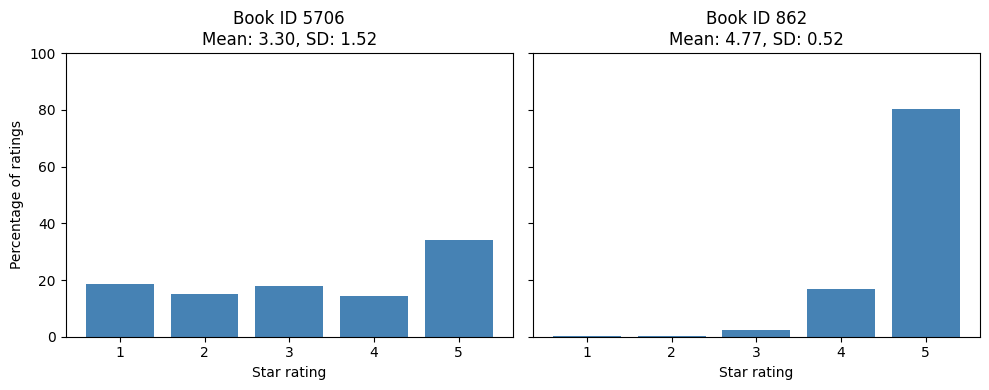

In [34]:
fig, axes = plots.plot_star_distributions(selected_books)
plt.show()

The two books illustrate contrasting levels of reader disagreement.
Ratings for حبيبتي بكماء are widely spread across the five star
scores, producing a standard deviation of approximately 1.52.

Ratings for Words of Radiance concentrate at four and five stars,
with around 80% awarding five stars. Its standard deviation is
approximately 0.52.

These examples show why average ratings alone cannot describe
how closely readers agree.

## Scoring and ranking

We adjust book ratings toward the dataset mean, accounting for the
number of ratings. The scoring module calculates adjusted scores
and compares the original and adjusted rankings.

In [36]:
ranked_books, baseline, prior_count = (
    scoring.adjusted_book_ranking(books_disagreement)
)

print(f"Baseline mean rating: {baseline:.3f}")
print(f"Adjustment strength: {prior_count:,.1f}")

ranking_columns = [
    "title",
    "rating_total",
    "rating_mean",
    "adjusted_score",
    "raw_rank",
    "adjusted_rank",
    "rank_change"
]

print("\nTop 10 by original mean rating:")
display(
    ranked_books.sort_values("raw_rank")[ranking_columns].head(10)
)

print("\nTop 10 by adjusted score:")
display(ranked_books[ranking_columns].head(10))

Baseline mean rating: 4.002
Adjustment strength: 23,832.5

Top 10 by original mean rating:


,title,rating_total,rating_mean,adjusted_score,raw_rank,adjusted_rank,rank_change
22,The Complete Calvin and Hobbes,29968,4.818306,4.456790,1,23,-22
23,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...",33424,4.772349,4.451783,2,24,-22
1,"Words of Radiance (The Stormlight Archive, #2)",108176,4.765142,4.627403,3,2,1
398,ESV Study Bible,10784,4.763724,4.239439,4,399,-395
504,Mark of the Lion Trilogy,9547,4.759087,4.218683,5,505,-500
72,It's a Magical World: A Calvin and Hobbes Coll...,23429,4.754492,4.375137,6,73,-67
162,There's Treasure Everywhere: A Calvin and Hobb...,17285,4.740989,4.312775,7,163,-156
0,"Harry Potter Boxset (Harry Potter, #1-7)",204125,4.740448,4.663266,8,1,7
178,The Indispensable Calvin and Hobbes,16911,4.730176,4.304356,9,179,-170
64,"Harry Potter Collection (Harry Potter, #1-6)",26274,4.727754,4.382656,10,65,-55



Top 10 by adjusted score:


,title,rating_total,rating_mean,adjusted_score,raw_rank,adjusted_rank,rank_change
0,"Harry Potter Boxset (Harry Potter, #1-7)",204125,4.740448,4.663266,8,1,7
1,"Words of Radiance (The Stormlight Archive, #2)",108176,4.765142,4.627403,3,2,1
2,A Court of Mist and Fury (A Court of Thorns an...,126491,4.719869,4.606090,12,3,9
3,Harry Potter and the Deathly Hallows (Harry Po...,1847395,4.612756,4.604980,37,4,33
4,"The Way of Kings (The Stormlight Archive, #1)",164477,4.640649,4.559847,26,5,21
5,"Clockwork Princess (The Infernal Devices, #3)",247984,4.587098,4.535816,54,6,48
6,Harry Potter and the Half-Blood Prince (Harry ...,1785676,4.537725,4.530671,93,7,86
7,"The Wise Man's Fear (The Kingkiller Chronicle,...",282349,4.574013,4.529505,63,8,55
8,The Name of the Wind (The Kingkiller Chronicle...,449372,4.553608,4.525837,78,9,69
9,Harry Potter and the Prisoner of Azkaban (Harr...,1969375,4.527866,4.521581,104,10,94


### Interpretation

Accounting for rating counts substantially changes the top-ranked
books. Only two books remain in both top-ten lists.

The Complete Calvin and Hobbes falls from rank 1 to 23, while
Harry Potter Boxset, Books 1–7 rises from rank 8 to 1.

Books with more ratings receive smaller adjustments toward the
baseline. Books with fewer ratings receive stronger adjustments.
A book can therefore rise in rank even if its adjusted score
is lower than its original mean.

These results depend on the chosen adjustment strength: the
median rating count of 23,832.5. The adjusted ranking represents
an alternative scoring rule rather than a definitive ranking
of book quality.

## Online book search

We extend Page Turners with an online search feature using the Open
Library API. Users can search by book title or author and retrieve
information such as publication year, edition count, and cover identifier.

The reusable search function is stored in `page_turners/api.py`.
It also handles invalid inputs, connection failures, and unexpected
API responses.

### Inspecting the selected book

We select the first result and display its description and up to ten subjects.

In [40]:
results = []
selected_book = None
details = None

try:
    results = api.search_books("Pride and Prejudice", max_results=5)
    display(pd.DataFrame(results))

    if results:
        selected_book = results[0]
        details = api.get_book_details(selected_book["open_library_id"])

        print(details["title"])
        print()
        print(details["description"] or "No description available.")
        print()
        print("Subjects:", ", ".join(details["subjects"][:10]))
    else:
        print("No books found.")
except api.ApiError as error:
    print(f"API request failed: {error}")


,open_library_id,title,authors,first_publish_year,edition_count,cover_id
0,/works/OL66554W,Pride and Prejudice,[Jane Austen],1813,4042,14348537
1,/works/OL15165350W,Pride and Prejudice,[Jane Austen],1813,132,13148521
2,/works/OL15093171W,Pride and Prejudice and Zombies,"[Seth Grahame-Smith, Katherine Kellgren]",2009,19,6260257
3,/works/OL5738118W,Pride and Prejudice [adaptation],[Fern Siegel],1997,4,14348568
4,/works/OL66597W,Novels (Pride and Prejudice / Sense and Sensib...,[Jane Austen],1949,28,12728748


Pride and Prejudice

Pride and Prejudice is an 1813 novel of manners written by Jane Austen. The novel follows the character development of Elizabeth Bennet, the dynamic protagonist of the book who learns about the repercussions of hasty judgments and comes to appreciate the difference between superficial goodness and actual goodness.

Mr. Bennet, owner of the Longbourn estate in Hertfordshire, has five daughters, but his property is entailed and can only be passed to a male heir. His wife also lacks an inheritance, so his family faces becoming very poor upon his death. Thus, it is imperative that at least one of the girls marry well to support the others, which is a motivation that drives the plot.

Subjects: Fiction, Romance, Historical, Regency, British and Irish fiction (fictional works by one author), Brothers and sisters, Courtship, Drama, English fiction, English literature, Families, Family, Family life


### Connecting online results to the ratings dataset

We find records with the same title and inspect their authors before
linking them to the online result.

In [41]:
title_matches = pd.DataFrame(
    columns=["book_id", "title", "authors", "average_rating", "ratings_count"]
)

if details is None or selected_book is None:
    print("Book matching skipped because no online details are available.")
else:
    selected_title = details["title"].strip().casefold()

    title_matches = books_clean.loc[
        books_clean["title"].str.strip().str.casefold().eq(selected_title),
        ["book_id", "title", "authors", "average_rating", "ratings_count"]
    ]

    print("Online authors:", ", ".join(selected_book["authors"]))

    if title_matches.empty:
        print("No exact title match found in the ratings dataset.")
    else:
        display(title_matches)

Online authors: Jane Austen


,book_id,title,authors,average_rating,ratings_count
9,10,Pride and Prejudice,Jane Austen,4.24,2035490


### Viewing the selected book’s rating statistics

We calculate reader disagreement and compare rankings before and after
adjusting for the number of ratings.

In [42]:
if title_matches.empty:
    print("No matched book is available for the selected-book statistics.")
else:
    selected_id = title_matches.iloc[0]["book_id"]

    selected_stats = ranked_books.loc[
        ranked_books["book_id"].eq(selected_id),
        [
            "title",
            "rating_mean",
            "rating_std",
            "adjusted_score",
            "raw_rank",
            "adjusted_rank",
            "rank_change",
        ]
    ]

    display(selected_stats)

,title,rating_mean,rating_std,adjusted_score,raw_rank,adjusted_rank,rank_change
390,Pride and Prejudice,4.243559,0.99021,4.240962,1639,391,1248


Pride and Prejudice has a mean rating of 4.244 and an adjusted score
of 4.241. Its ranking improves by 1,248 positions, from 1,639 to 391.

Its large rating count keeps its adjusted score close to its observed
mean. Books with fewer ratings are pulled more strongly toward the
dataset baseline, which changes their relative positions.

### Ranking from the scoring module

We display the ten highest-ranked books using the dedicated scoring module.


In [44]:
display(
    ranked_books[
        [
            "title",
            "rating_mean",
            "rating_total",
            "adjusted_score",
            "raw_rank",
            "adjusted_rank",
            "rank_change",
        ]
    ].head(10)
)

,title,rating_mean,rating_total,adjusted_score,raw_rank,adjusted_rank,rank_change
0,"Harry Potter Boxset (Harry Potter, #1-7)",4.740448,204125,4.663266,8,1,7
1,"Words of Radiance (The Stormlight Archive, #2)",4.765142,108176,4.627403,3,2,1
2,A Court of Mist and Fury (A Court of Thorns an...,4.719869,126491,4.606090,12,3,9
3,Harry Potter and the Deathly Hallows (Harry Po...,4.612756,1847395,4.604980,37,4,33
4,"The Way of Kings (The Stormlight Archive, #1)",4.640649,164477,4.559847,26,5,21
5,"Clockwork Princess (The Infernal Devices, #3)",4.587098,247984,4.535816,54,6,48
6,Harry Potter and the Half-Blood Prince (Harry ...,4.537725,1785676,4.530671,93,7,86
7,"The Wise Man's Fear (The Kingkiller Chronicle,...",4.574013,282349,4.529505,63,8,55
8,The Name of the Wind (The Kingkiller Chronicle...,4.553608,449372,4.525837,78,9,69
9,Harry Potter and the Prisoner of Azkaban (Harr...,4.527866,1969375,4.521581,104,10,94


### Sensitivity to the adjustment strength

We compare adjustment strengths from 0.1 to 5 times the median rating
count. We examine rank correlation, overlap with the original top ten,
and the median absolute change in rank.

These measures describe sensitivity; they do not identify an optimal m.

In [45]:
reference_m = prior_count
multipliers = [0.1, 0.25, 0.5, 1, 2, 5]

# Original top ten, using book_id to order tied scores consistently.
raw_top10 = set(
    books_disagreement.sort_values(
        ["rating_mean", "book_id"],
        ascending=[False, True]
    ).head(10)["book_id"]
)

rows = []
rankings_by_m = {}

for multiplier in multipliers:
    if multiplier == 1:
        ranking = ranked_books
        m = prior_count
    else:
        ranking, _, m = scoring.adjusted_book_ranking(
            books_disagreement,
            prior_count=reference_m * multiplier
        )

    rankings_by_m[multiplier] = ranking

    adjusted_top10 = set(ranking.head(10)["book_id"])

    rows.append({
        "median_multiplier": multiplier,
        "m": m,
        "rank_correlation": ranking["raw_rank"].corr(
            ranking["adjusted_rank"],
            method="spearman"
        ),
        "top10_overlap": len(raw_top10 & adjusted_top10),
        "median_abs_rank_change": (
            ranking["rank_change"].abs().median()
        ),
    })

sensitivity_summary = pd.DataFrame(rows)

display(sensitivity_summary.round(3))

,median_multiplier,m,rank_correlation,top10_overlap,median_abs_rank_change
0,0.10,2383.250,0.999,8,63.0
1,0.25,5958.125,0.997,6,136.0
2,0.50,11916.250,0.992,4,223.0
3,1.00,23832.500,0.982,2,334.0
4,2.00,47665.000,0.969,2,438.0
5,5.00,119162.500,0.952,1,540.0


### Comparing the adjusted top ten

We compare the books occupying the first ten positions at half,
one and twice the median rating count.

In [46]:
top10_comparison = pd.DataFrame({
    f"{factor:g} × median": (
        rankings_by_m[factor]["title"].head(10).to_numpy()
    )
    for factor in [0.5, 1, 2]
})

top10_comparison.index = range(1, 11)
top10_comparison.index.name = "Position"

display(top10_comparison)

,0.5 × median,1 × median,2 × median
Position,,,
1,"Harry Potter Boxset (Harry Potter, #1-7)","Harry Potter Boxset (Harry Potter, #1-7)","Harry Potter Boxset (Harry Potter, #1-7)"
2,"Words of Radiance (The Stormlight Archive, #2)","Words of Radiance (The Stormlight Archive, #2)",Harry Potter and the Deathly Hallows (Harry Po...
3,A Court of Mist and Fury (A Court of Thorns an...,A Court of Mist and Fury (A Court of Thorns an...,"Words of Radiance (The Stormlight Archive, #2)"
4,Harry Potter and the Deathly Hallows (Harry Po...,Harry Potter and the Deathly Hallows (Harry Po...,Harry Potter and the Half-Blood Prince (Harry ...
5,"The Way of Kings (The Stormlight Archive, #1)","The Way of Kings (The Stormlight Archive, #1)",A Court of Mist and Fury (A Court of Thorns an...
6,The Complete Calvin and Hobbes,"Clockwork Princess (The Infernal Devices, #3)",Harry Potter and the Prisoner of Azkaban (Harr...
7,The Essential Calvin and Hobbes: A Calvin and ...,Harry Potter and the Half-Blood Prince (Harry ...,Harry Potter and the Goblet of Fire (Harry Pot...
8,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","The Wise Man's Fear (The Kingkiller Chronicle,...",The Name of the Wind (The Kingkiller Chronicle...
9,"Clockwork Princess (The Infernal Devices, #3)",The Name of the Wind (The Kingkiller Chronicle...,"The Way of Kings (The Stormlight Archive, #1)"


The Harry Potter Boxset remains first across all three adjustment
strengths. Five books appear in every top-ten list, while the default
and twice-median settings share eight books.

However, both membership and ordering change with m. We retain the
median rating count as an illustrative default, rather than an
optimised value.